In [1]:
import pandas as pd
import numpy as np
import time
import psutil
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score

In [2]:
def get_process_memory():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

In [3]:
# 1. Fetch and Preprocess Data
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/forest-fires/forestfires.csv'
df = pd.read_csv(url)
df['fire_risk'] = (df['area'] > 0).astype(int)
df = df.drop('area', axis=1)
df = pd.get_dummies(df, columns=['month', 'day'], drop_first=True)

In [4]:
X = df.drop('fire_risk', axis=1)
y = df['fire_risk']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
df.head()

,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,...,month_may,month_nov,month_oct,month_sep,day_mon,day_sat,day_sun,day_thu,day_tue,day_wed
0,7,5,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,...,False,False,False,False,False,False,False,False,False,False
1,7,4,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,...,False,False,True,False,False,False,False,False,True,False
2,7,4,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,...,False,False,True,False,False,True,False,False,False,False
3,8,6,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,...,False,False,False,False,False,False,False,False,False,False
4,8,6,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,...,False,False,False,False,False,False,True,False,False,False


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
models = {
    "RF (Parallel)": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    "RF (Sequential)": RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=42),
    "SVM": SVC(kernel='rbf', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

In [7]:
# Data storage for plotting
plot_names = []
plot_train_times = []
plot_mem_deltas = []
print("Training Models (Running 5 iterations to average out CPU fluctuations)...\n" + "="*60)
ITERATIONS = 5

Training Models (Running 5 iterations to average out CPU fluctuations)...


In [8]:
for name, model in models.items():
    train_times = []
    infer_times = []
    mem_deltas = []
    
    # Run multiple times to get stable hardware averages
    for _ in range(ITERATIONS):
        mem_before = get_process_memory()
        start_train = time.perf_counter()
        
        model.fit(X_train_scaled, y_train)
        
        end_train = time.perf_counter()
        mem_after = get_process_memory()
        
        start_infer = time.perf_counter()
        predictions = model.predict(X_test_scaled)
        end_infer = time.perf_counter()
        
        train_times.append((end_train - start_train) * 1000)
        infer_times.append((end_infer - start_infer) * 1000)
        mem_deltas.append(abs(mem_after - mem_before))
    
    # Calculate Averages
    avg_train = np.mean(train_times)
    avg_infer = np.mean(infer_times)
    avg_mem = np.mean(mem_deltas)
    
    # ML Metrics (only need to calculate once since random_state is fixed)
    acc = accuracy_score(y_test, predictions)
    rec = recall_score(y_test, predictions)
    
    # Store for graphing
    plot_names.append(name)
    plot_train_times.append(avg_train)
    plot_mem_deltas.append(avg_mem)
    
    print(f"--- {name} ---")
    print(f"ML Metrics: Accuracy: {acc*100:.2f}% | Recall: {rec*100:.2f}%")
    print(f"Avg Training Latency : {avg_train:.2f} ms")
    print(f"Avg Inference Latency: {avg_infer:.2f} ms")
    print(f"Avg Memory Delta     : {avg_mem:.2f} MB\n")

--- RF (Parallel) ---
ML Metrics: Accuracy: 50.96% | Recall: 54.72%
Avg Training Latency : 380.33 ms
Avg Inference Latency: 54.15 ms
Avg Memory Delta     : 0.40 MB

--- RF (Sequential) ---
ML Metrics: Accuracy: 50.96% | Recall: 54.72%
Avg Training Latency : 411.55 ms
Avg Inference Latency: 14.40 ms
Avg Memory Delta     : 0.29 MB

--- SVM ---
ML Metrics: Accuracy: 57.69% | Recall: 73.58%
Avg Training Latency : 21.43 ms
Avg Inference Latency: 9.08 ms
Avg Memory Delta     : 0.18 MB

--- Gradient Boosting ---
ML Metrics: Accuracy: 52.88% | Recall: 64.15%
Avg Training Latency : 365.61 ms
Avg Inference Latency: 1.21 ms
Avg Memory Delta     : 0.03 MB



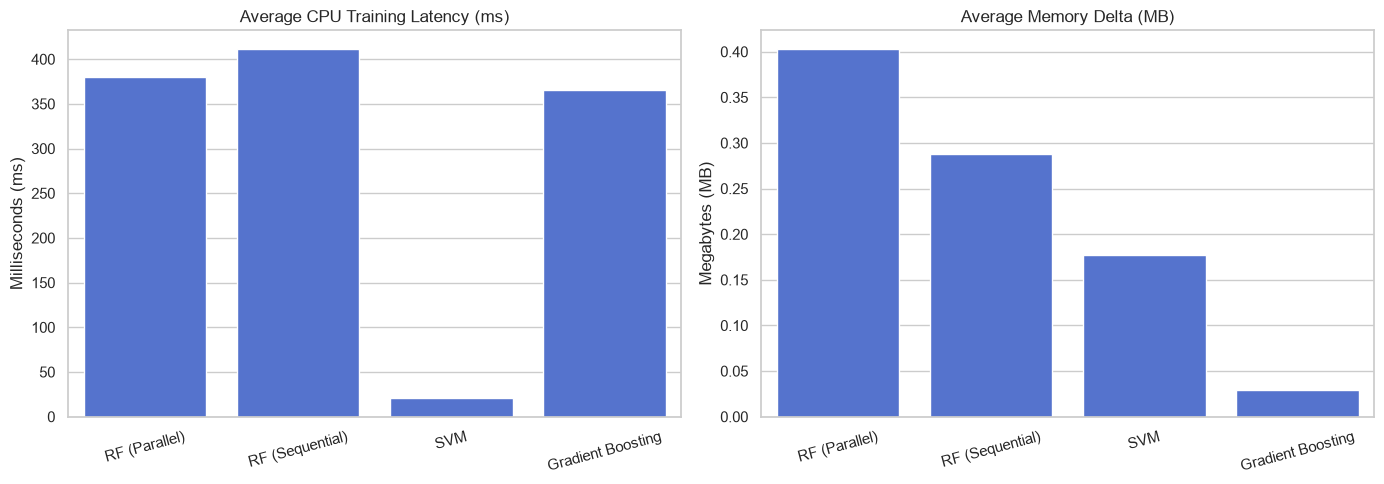

In [13]:
# Generate Visualizations
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.barplot(x=plot_names, y=plot_train_times, ax=axes[0], color="royalblue")
axes[0].set_title('Average CPU Training Latency (ms)')
axes[0].set_ylabel('Milliseconds (ms)')
axes[0].tick_params(axis='x', rotation=15)


sns.barplot(x=plot_names, y=plot_mem_deltas, ax=axes[1], color="royalblue")
axes[1].set_title('Average Memory Delta (MB)')
axes[1].set_ylabel('Megabytes (MB)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


FINAL HARDWARE VERDICT
The most resource-efficient model for edge deployment is: SVM
 - CPU Training Latency : 21.43 ms
 - Memory Consumption   : 0.18 MB


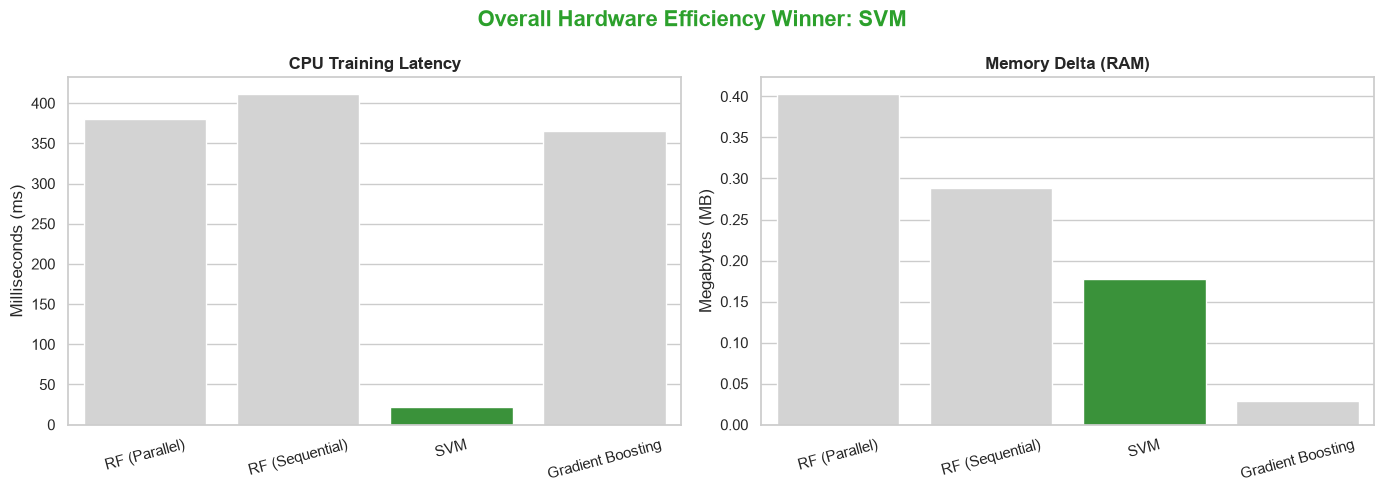

In [14]:
# Normalize the metrics to combine them fairly
max_latency = max(plot_train_times)
max_memory = max(plot_mem_deltas)

combined_scores = []
for i in range(len(plot_names)):
    # Calculate efficiency: lower score is better
    norm_latency = plot_train_times[i] / max_latency
    norm_memory = plot_mem_deltas[i] / max_memory
    combined_scores.append(norm_latency + norm_memory)

# Find the index of the lowest combined score
best_overall_index = np.argmin(combined_scores)
overall_winner = plot_names[best_overall_index]

print("FINAL HARDWARE VERDICT")
print(f"The most resource-efficient model for edge deployment is: {overall_winner}")
print(f" - CPU Training Latency : {plot_train_times[best_overall_index]:.2f} ms")
print(f" - Memory Consumption   : {plot_mem_deltas[best_overall_index]:.2f} MB")


# 2. Generate Visualizations Highlighting the Single Winner
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Create color array: highlight the OVERALL winner in bright green, others in gray
colors = ['#2ca02c' if i == best_overall_index else 'lightgray' for i in range(len(plot_names))]

# 1. Plot Average CPU Training Latency
sns.barplot(
    x=plot_names, y=plot_train_times, ax=axes[0], 
    palette=colors, hue=plot_names, legend=False
)
axes[0].set_title(f'CPU Training Latency', fontweight='bold')
axes[0].set_ylabel('Milliseconds (ms)')
axes[0].tick_params(axis='x', rotation=15)

# 2. Plot Average Memory Delta
sns.barplot(
    x=plot_names, y=plot_mem_deltas, ax=axes[1], 
    palette=colors, hue=plot_names, legend=False
)
axes[1].set_title(f'Memory Delta (RAM)', fontweight='bold')
axes[1].set_ylabel('Megabytes (MB)')
axes[1].tick_params(axis='x', rotation=15)

# Add a massive title spanning the entire figure to announce the winner
fig.suptitle(f'Overall Hardware Efficiency Winner: {overall_winner}', fontsize=16, fontweight='bold', color='#2ca02c')

plt.tight_layout()
plt.show()